# Project 11: Handwritten Digit Classification Using CNN


## Objective
To build a Convolutional Neural Network (CNN) that classifies handwritten digits from the MNIST dataset and evaluates its performance using standard classification metrics.

## Introduction
The MNIST dataset contains grayscale images of handwritten digits from 0 to 9. A CNN can learn image patterns using convolutional and pooling layers, then use those learned features to predict the correct digit. In this project, the images are preprocessed, a basic CNN is trained, and its predictions are evaluated on unseen test images.

## Task 1: Load and preprocess the MNIST dataset

The pixel values are normalized from the range 0–255 to 0–1. A channel dimension is added because the CNN expects each grayscale image to have an explicit channel.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from sklearn.metrics import confusion_matrix, classification_report

# Load MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalize pixels and add the grayscale channel dimension
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)
print("Number of digit classes:", len(np.unique(y_train)))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28, 1)
Testing images: (10000, 28, 28, 1)
Number of digit classes: 10


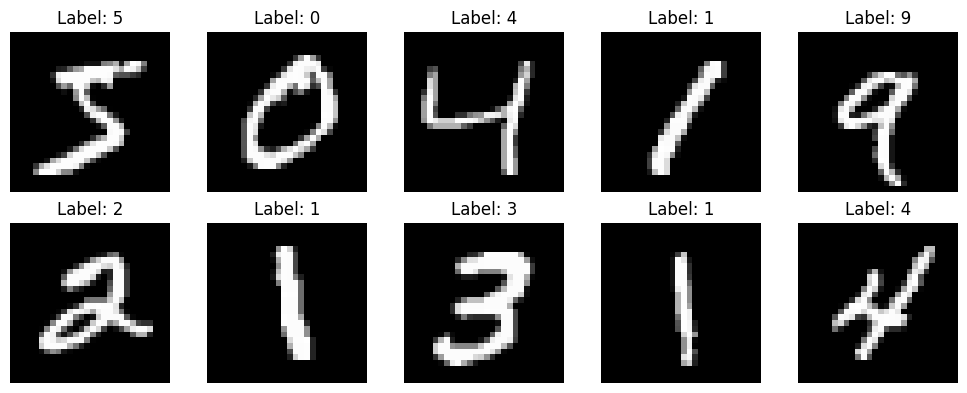

In [2]:
# Display a few training images
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].squeeze(), cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## Task 2: Build and train a basic CNN model

The first convolutional layer detects simple image patterns. Max pooling reduces the feature-map dimensions, and the second convolutional layer learns more detailed features. The dense layers use these features to classify each image into one of the ten digit classes.

In [3]:
cnn_model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Train the CNN; validation data is taken from the training set
history = cnn_model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.9245 - loss: 0.2572 - val_accuracy: 0.9783 - val_loss: 0.0725
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9778 - loss: 0.0706 - val_accuracy: 0.9827 - val_loss: 0.0606
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9848 - loss: 0.0493 - val_accuracy: 0.9877 - val_loss: 0.0434
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9885 - loss: 0.0382 - val_accuracy: 0.9875 - val_loss: 0.0400
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9904 - loss: 0.0319 - val_accuracy: 0.9895 - val_loss: 0.0369


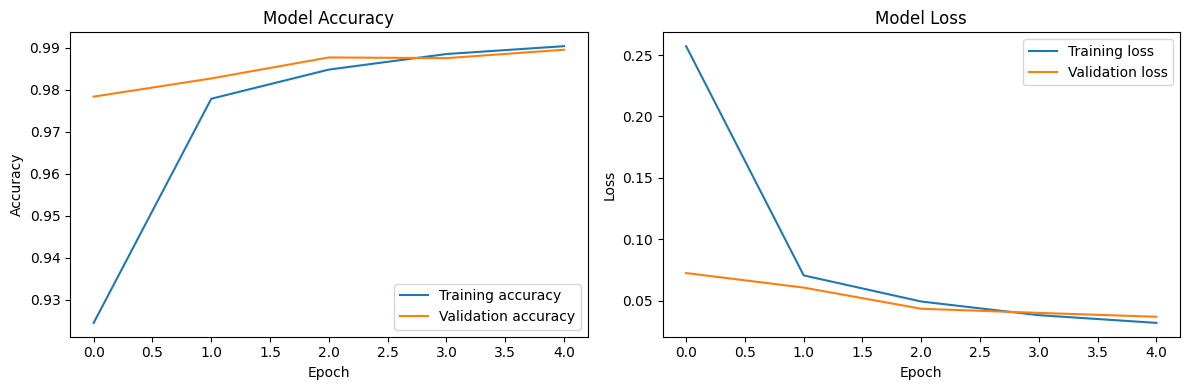

In [5]:
# Plot accuracy and loss across training epochs
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model Loss")
plt.legend()

plt.tight_layout()
plt.show()

## Task 3: Evaluate the trained model

The model is evaluated on the separate test set. A confusion matrix shows correct predictions along the diagonal and which digit pairs are confused. The classification report gives precision, recall, and F1-score for every digit class.

In [6]:
test_loss, test_accuracy = cnn_model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

Test loss: 0.0326
Test accuracy: 0.9885


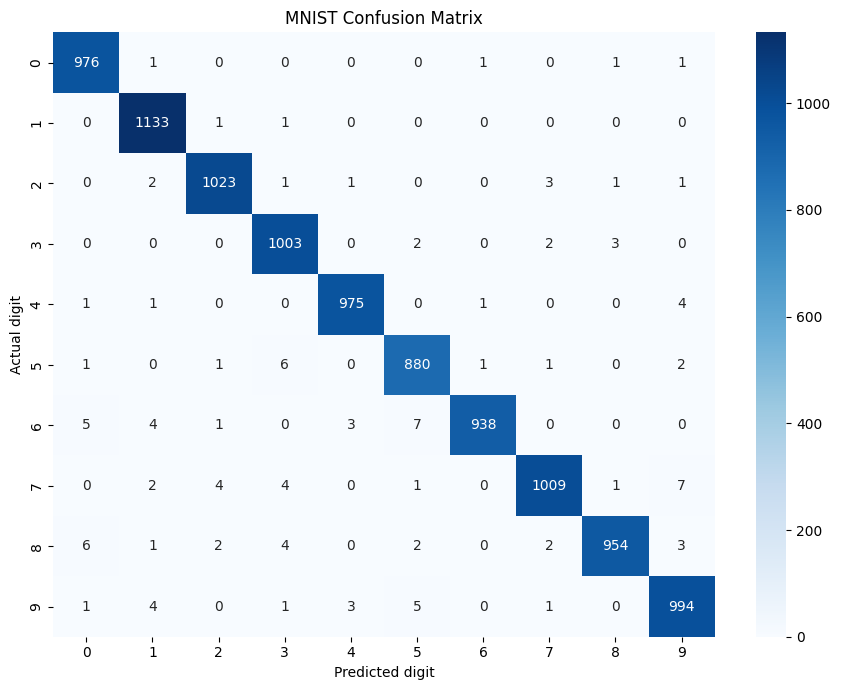

In [7]:
# Predict classes for the test images
probabilities = cnn_model.predict(X_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel("Predicted digit")
plt.ylabel("Actual digit")
plt.title("MNIST Confusion Matrix")
plt.tight_layout()
plt.show()

In [8]:
# Precision, recall, and F1-score for each digit
print(classification_report(
    y_test,
    y_pred,
    labels=list(range(10)),
    target_names=[str(i) for i in range(10)],
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

           0     0.9859    0.9959    0.9909       980
           1     0.9869    0.9982    0.9926      1135
           2     0.9913    0.9913    0.9913      1032
           3     0.9833    0.9931    0.9882      1010
           4     0.9929    0.9929    0.9929       982
           5     0.9810    0.9865    0.9838       892
           6     0.9968    0.9791    0.9879       958
           7     0.9912    0.9815    0.9863      1028
           8     0.9938    0.9795    0.9866       974
           9     0.9822    0.9851    0.9837      1009

    accuracy                         0.9885     10000
   macro avg     0.9885    0.9883    0.9884     10000
weighted avg     0.9885    0.9885    0.9885     10000



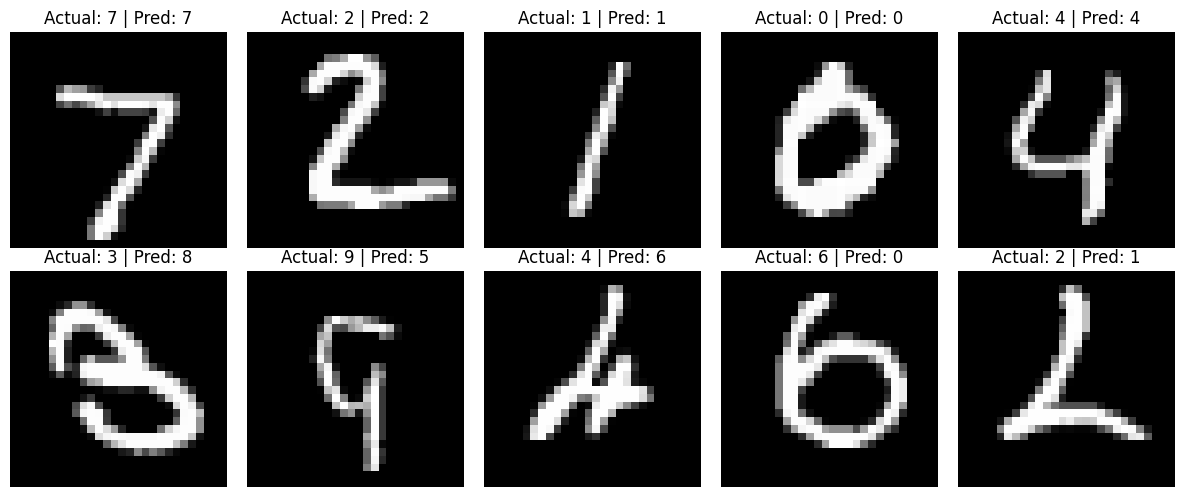

Incorrect predictions in test set: 115


In [9]:
# Display sample predictions, including any incorrect examples if available
incorrect_indices = np.where(y_pred != y_test)[0]
correct_indices = np.where(y_pred == y_test)[0]

chosen = list(correct_indices[:5])
chosen += list(incorrect_indices[:5])

plt.figure(figsize=(12, 5))
for position, index in enumerate(chosen[:10]):
    plt.subplot(2, 5, position + 1)
    plt.imshow(X_test[index].squeeze(), cmap="gray")
    plt.title(f"Actual: {y_test[index]} | Pred: {y_pred[index]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

print("Incorrect predictions in test set:", len(incorrect_indices))

## Expected Output / Result

The CNN is trained to classify handwritten MNIST images into ten digit categories, from 0 to 9. After training, its test accuracy and test loss are displayed. The confusion matrix summarizes correct and incorrect predictions for each digit, while the classification report provides precision, recall, and F1-score for every class. Sample predictions make it possible to visually compare the actual digit with the model's predicted digit and observe examples of misclassification.

## Conclusion

This project demonstrates the main steps in image classification with a CNN: loading and normalizing image data, learning features through convolution and pooling, training a classification model, and evaluating its predictions. The confusion matrix and classification report help identify which digits the model classifies well and which may require further improvement.